# Do major concerts coincide with more nearby NYC crashes?

**Main finding:** The two venues show opposite patterns: the 4 Citi Field nights had 13 crashes versus 3.9 expected; the 15 MSG nights had 23 versus 32.6 expected. The combined average hides this difference.

**Combined result:** Across 19 selected concert nights, crashes within 1 km during 16:00–02:00 averaged **1.89**, versus **1.92** on matched reference nights (**-1.3%**). This is an association in a small selected sample, not a causal concert effect.

There were **36 observed crashes**, compared with **36.5 matched expected crashes** (sum of event-specific reference averages). Injury/fatal crashes averaged 0.58 versus 0.67 (-13.5%).



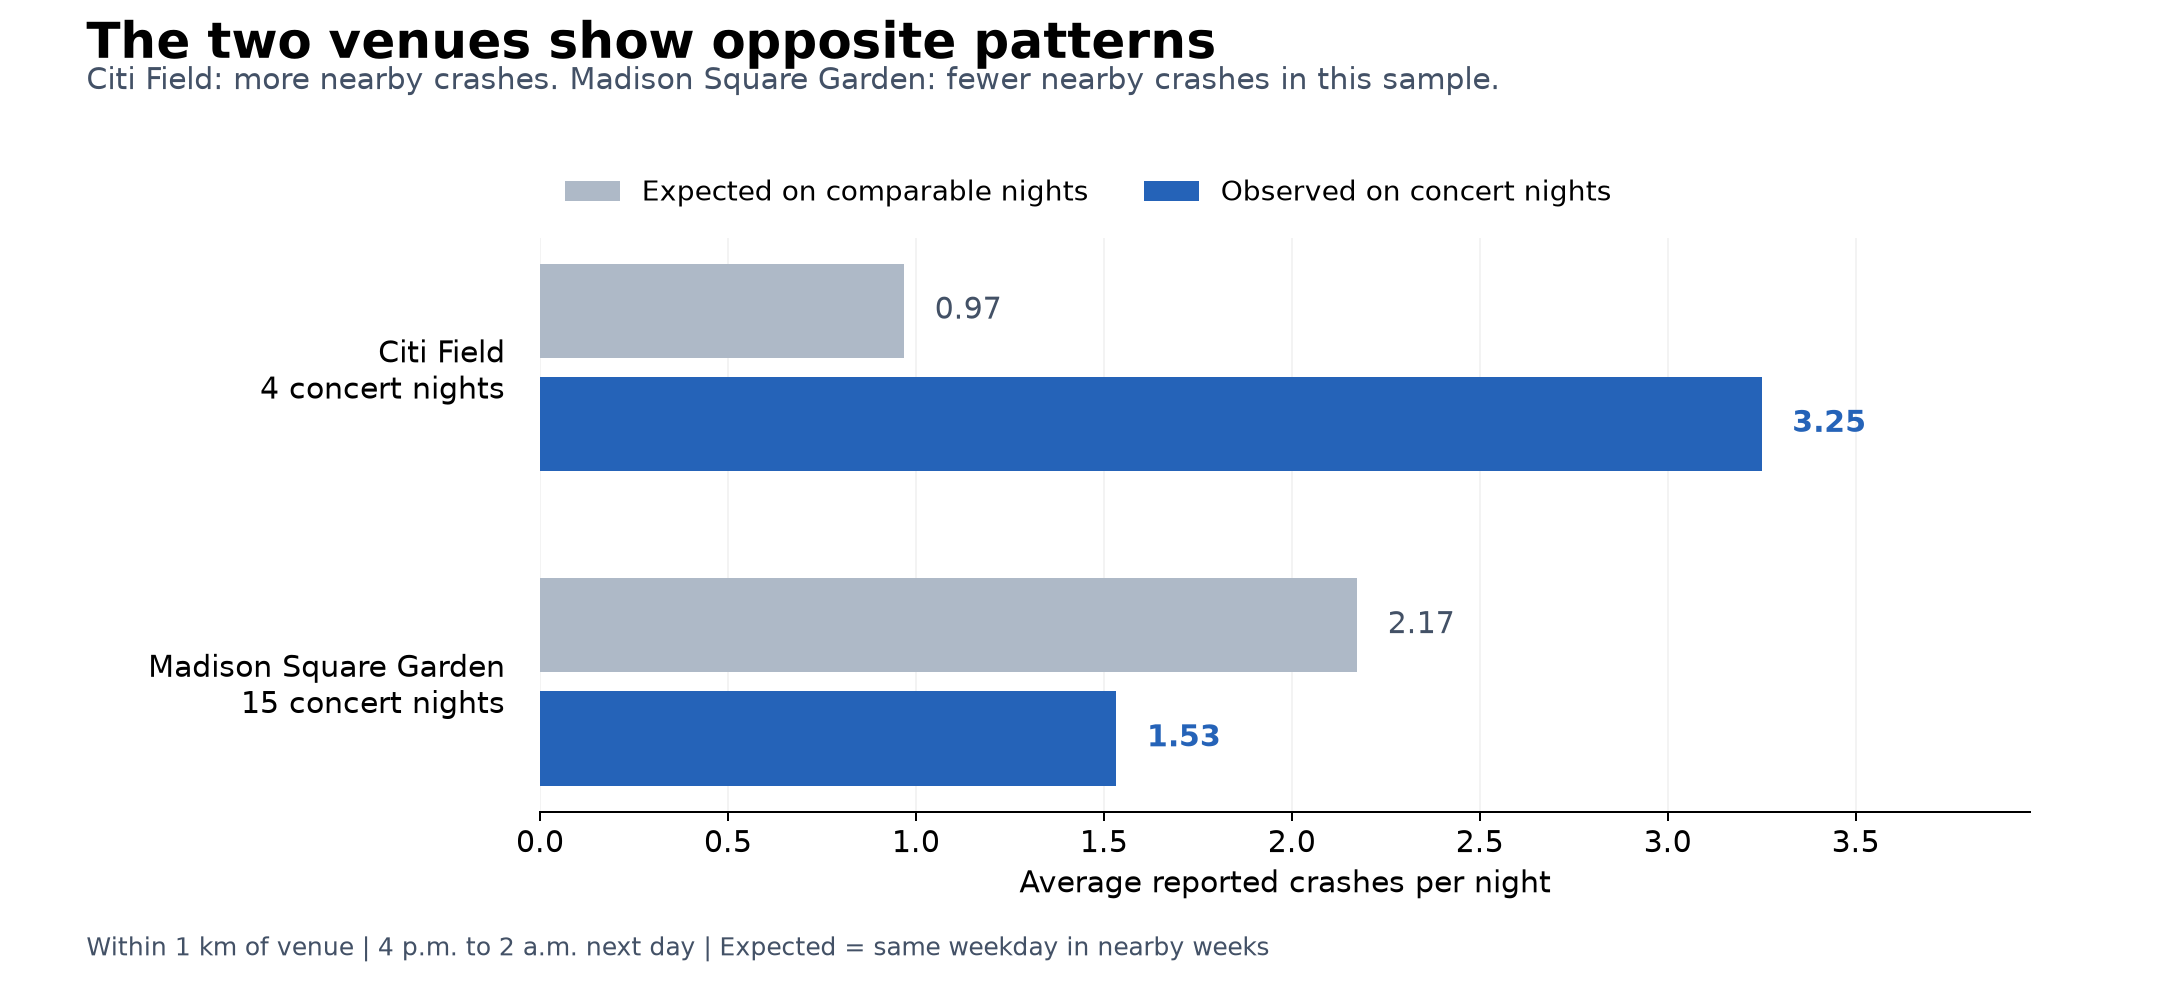

The blue bar shows concert nights; the gray bar shows the matched expectation. Both use average crashes per night, so the different sample sizes are visible in the labels.

## Results by artist

| Artist | Nights | Concert crashes/night | Reference crashes/night | Difference |
|---|---:|---:|---:|---:|
| Beyonce | 2 | 4.00 | 1.38 | +190.9% |
| BTS | 1 | 3.00 | 0.88 | +242.9% |
| Pink | 1 | 2.00 | 0.25 | +700.0% |
| Harry Styles | 15 | 1.53 | 2.17 | -29.5% |

The pooled result is dominated by the 15 MSG shows. Citi Field contributes only four nights. Large artist percentages arise from very small baseline counts and should not be treated as stable estimates.



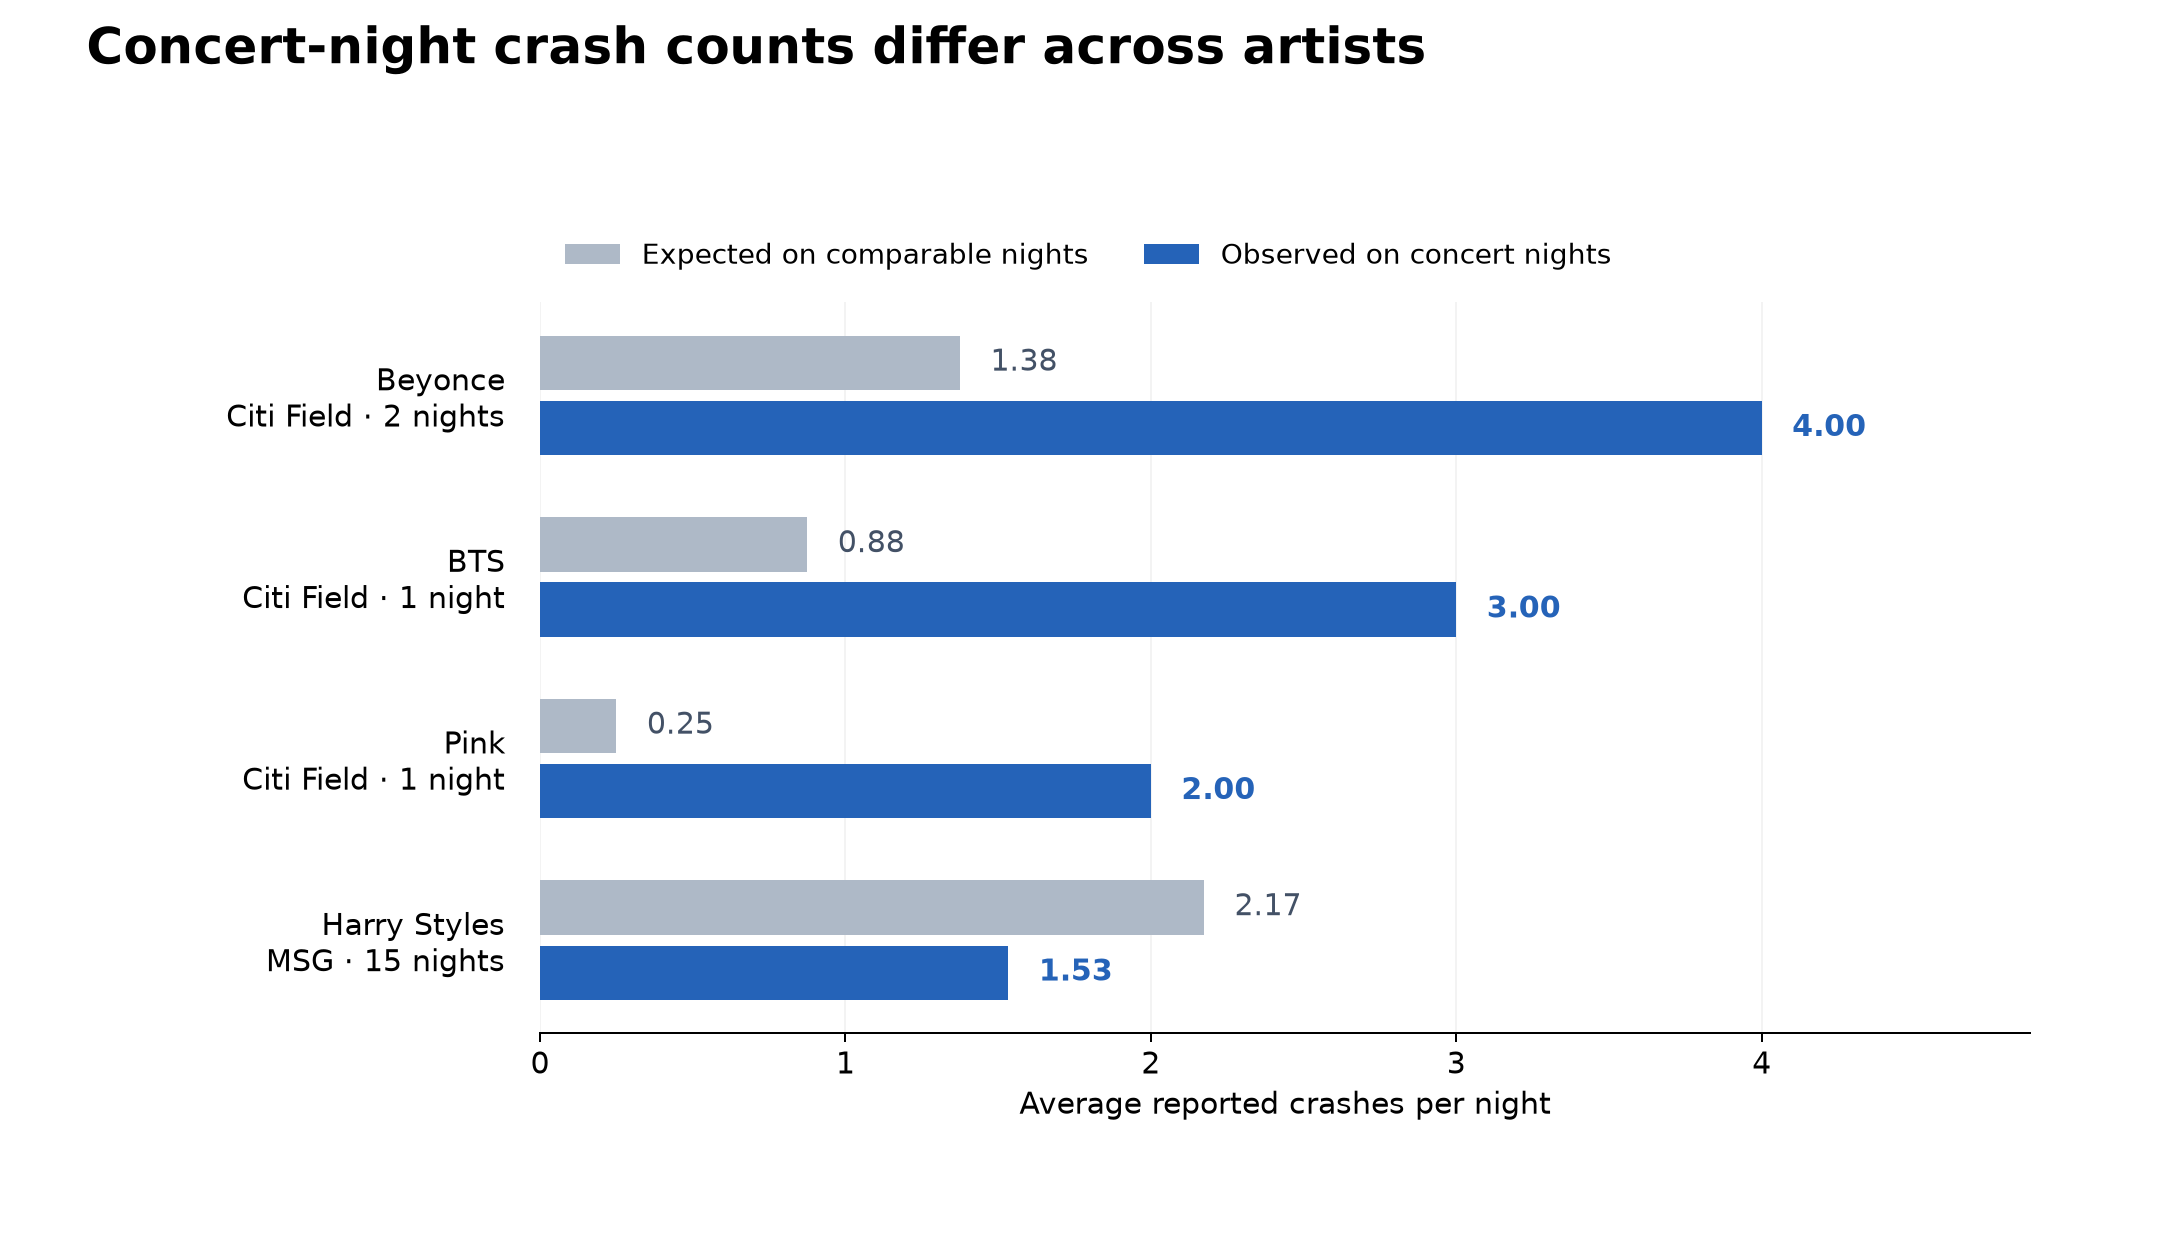

Compare each blue bar with its gray bar. A large percentage increase can represent only a few extra crashes when the expected count is small.

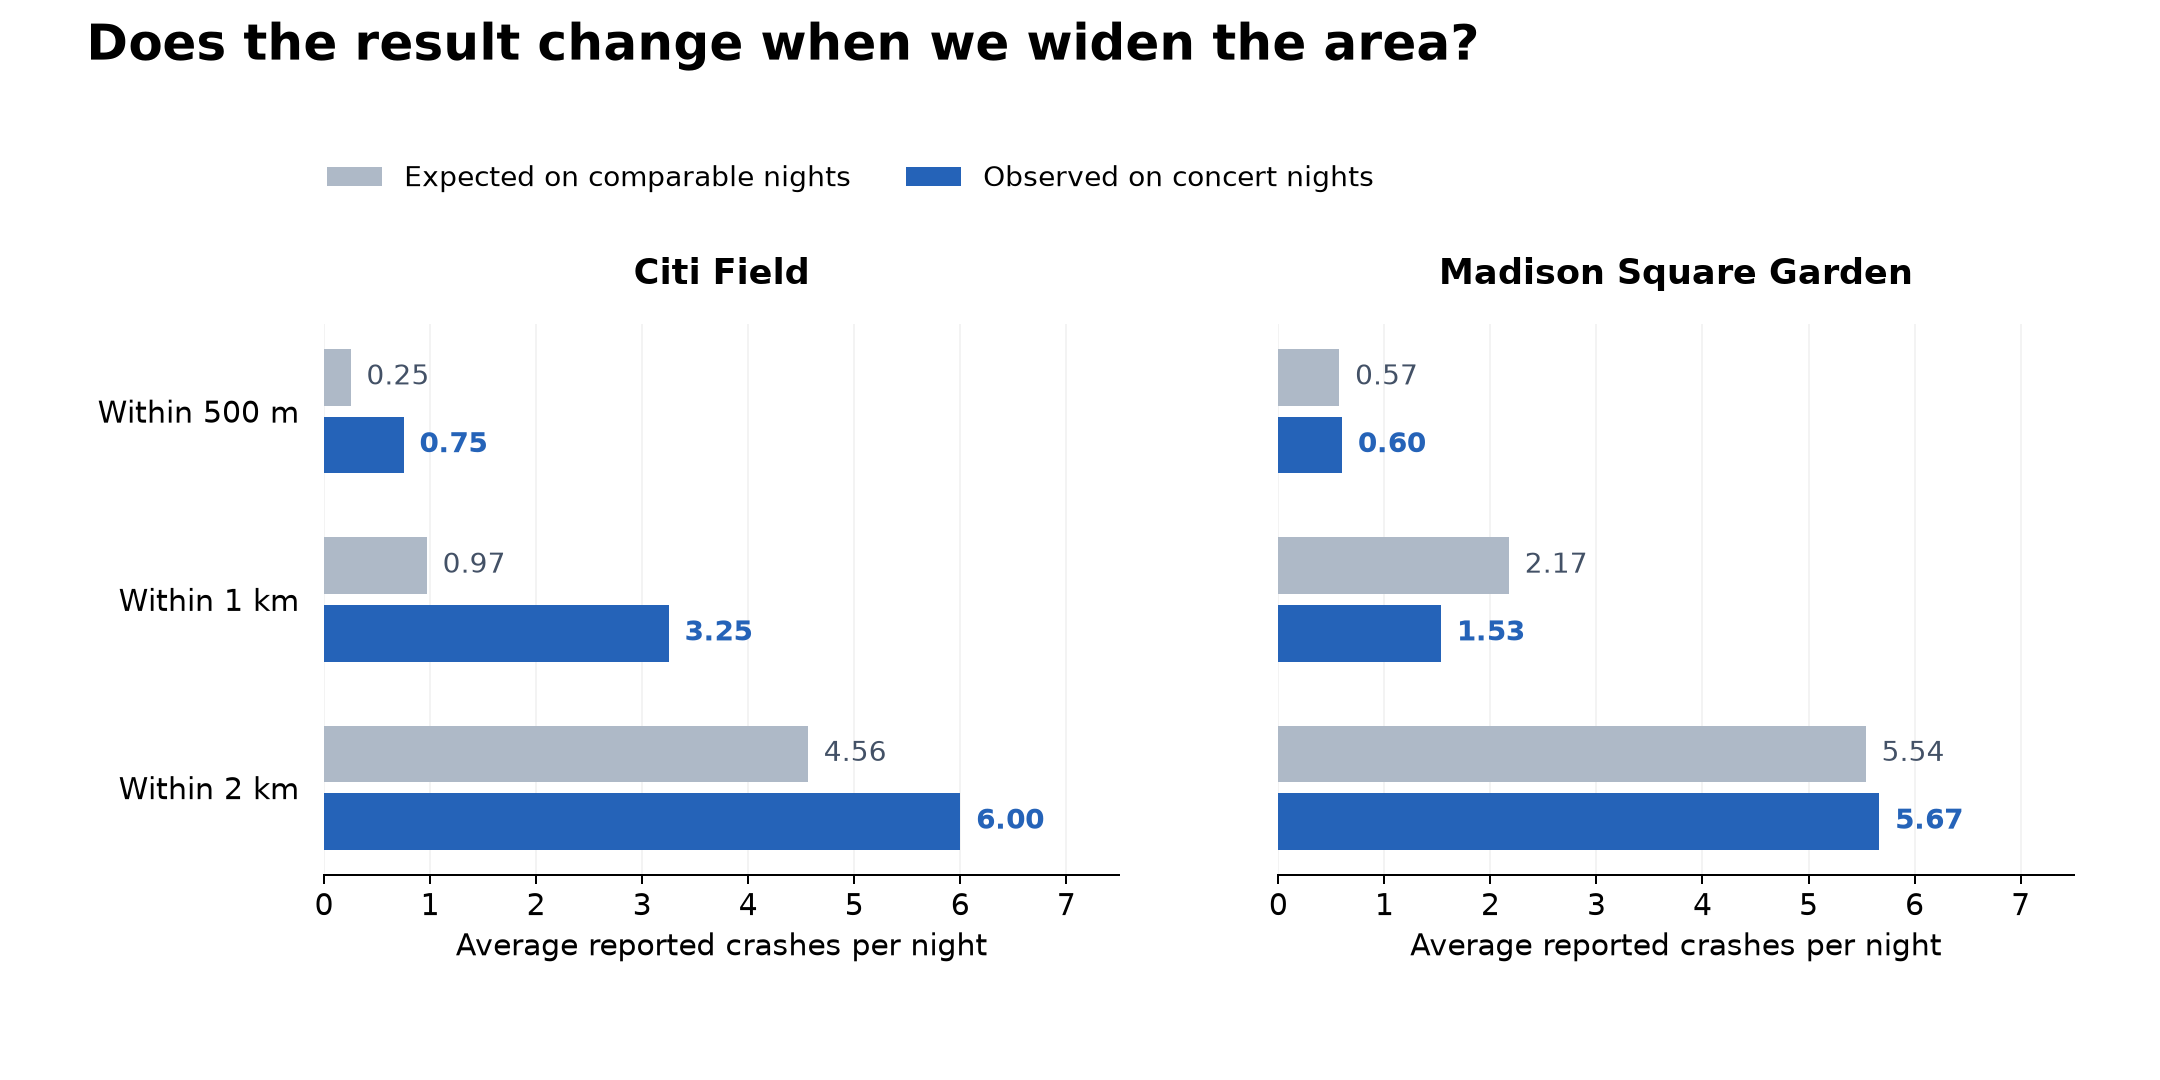

Wider areas include more roads and crashes. Compare observed with expected within each row; the overlapping areas are not independent samples.

## Design

The calendar contains Beyonce (Citi Field, June 7–8, 2016), BTS (Citi Field, October 6, 2018), Pink (Citi Field, August 3, 2023), and Harry Styles (15 MSG dates in August–September 2022). Event dates were transcribed from online sources accessed October 17, 2026; this is a curated pilot, not a complete NYC event database.
Each concert is compared with the same venue, clock window, and weekday at ±7, ±14, ±21 and ±28 days. Other listed concerts at that venue are excluded from reference nights. Each concert receives equal weight, even when reference-night counts differ. Midnight–02:00 crashes belong to the preceding event date. All zero-count venue windows are retained. No raw collision rows are displayed or exported.
Coordinates use approximate venue centers and haversine distance. Local results exclude missing/invalid coordinates; citywide counts retain them. These are all reported vehicle-involved crashes, not passenger-car-only crashes. Injury outcomes count people separately from crash frequency.

## Sensitivity and interpretation

- 0.5 km: +24.9% in crash counts.
- 1 km: -1.3% in crash counts.
- 2 km: +7.6% in crash counts.
- 2–5 km ring: +3.9% in crash counts.
- citywide: -1.1% in crash counts.
- Morning placebo (06:00–12:00, 1 km): -0.7%. A morning difference can flag residual date-level confounding; early arrivals may also affect it.
- Near-versus-ring ratio of count ratios: 0.95. Values above 1 mean the near-zone change exceeds the 2–5 km ring change; spillovers and different road environments limit this comparison.

**What this can support:** selected concert nights had the observed count differences shown above. It cannot establish whether a concert caused a crash, whether attendees were involved, or whether risk per driver increased.
**Limits:** Harry Styles supplies 15/19 nights; the remaining artist samples have one or two nights. References can include unlisted concerts, Mets games, US Open sessions, holidays and other events. Weather, construction, traffic volume, attendance and transit use are not controlled. Reference dates are reused, and consecutive shows are correlated. No significance tests or confidence intervals are claimed. Radius and time sensitivities are exploratory, not independent confirmations. Missing geocodes can bias local comparisons. The 2016–2023 dates span reporting and travel changes, so artist contrasts are especially confounded.
**Data audit:** 2,269,187 input rows; coverage 2012-07-01 to 2026-06-11; valid NYC-area coordinates in 90.3% of selected calendar-day records. All selected event/reference dates and following days lie inside dataset coverage. Duplicate IDs removed from selected records: 0.

## Reproduce

Run the six code cells in this notebook in order, from the repository root or notebooks folder. The concert calendar is embedded. The only data input required is the local `data/motor_vehicle_collisions.csv`; install numpy, pandas and matplotlib in the notebook environment. Cells rebuild comparison tables and PNG graphs without the companion script or precomputed outputs.

## Sources

- [beyonce_mlb](https://www.mlb.com/amp/news/beyonce-to-perform-at-citi-field-june-7-8-c163902796.html): Beyonce: June 7–8, 2016, Citi Field
- [bts_aeg](https://aegworldwide.com/press-center/press-releases/bts-confirms-highly-anticipated-details-their-first-stadium-show-us): BTS: October 6, 2018, Citi Field
- [pink_mlb](https://www.mlb.com/press-release/press-release-pink-summer-carnival-at-citi-field-in-2023): Pink: August 3, 2023, Citi Field
- [harry_tour](https://www.seatstories.com/news/harry-styles-five-dates-added-new-york-los-angeles-harrys-house-tickets): Harry Styles individual dates; syndicated TicketNews tour announcement. September 8 also cross-checked against the retrospective performance record.
- [harry_msg](https://www.msgentertainment.com/msg-is-harrys-house-harry-styles-makes-history-at-madison-square-garden-as-banner-is-raised-to-the-rafters-following-15-consecutive-nights-of-love-on-tour-at-the-garden/): Venue confirmation of 15 shows, August 20–September 21, 2022
- [harry_fader](https://www.thefader.com/2022/08/26/harry-styles-uk-eu-tour-dates-2023): Additional published tour schedule cross-check: August 28 and all nine September MSG dates
- [harry_sep8](https://www.setlist.fm/setlist/harry-styles/2022/madison-square-garden-new-york-ny-5bb0f7fc.html): Supplemental retrospective confirmation of September 8 performance
- [crashes](https://catalog.data.gov/dataset/motor-vehicle-collisions-crashes): City of New York police-reported motor vehicle collisions; local competition CSV

City of New York—Motor Vehicle Collisions—Crashes. (n.d.). Data.Gov. Retrieved October 14, 2026 (competition dataset acknowledgment).

## Reproduce the analysis and graphs
Run the code cells below in order. The event calendar is embedded, so this notebook needs only the local `data/motor_vehicle_collisions.csv` and Python packages numpy, pandas and matplotlib. It does not require the companion script or exported summary CSVs. No individual crash rows are displayed.

### 1. Set up packages, paths and distance calculation

In [ ]:
"""Separate, descriptive concert/crash study. Run from any working directory."""
from pathlib import Path
import os, json, hashlib, base64, html
os.environ.setdefault('MPLCONFIGDIR', '/tmp/nyc-event-mpl')
import numpy as np
import pandas as pd
import matplotlib
from IPython import get_ipython
if get_ipython() is not None:
    get_ipython().run_line_magic('matplotlib', 'inline')
import matplotlib.pyplot as plt

ROOT = Path.cwd() if (Path.cwd() / 'data').exists() else Path.cwd().parent
OUT = ROOT / 'outputs/event_analysis'
OUT.mkdir(parents=True, exist_ok=True)
CALENDAR = ROOT / 'data/external/events/concert_calendar.csv'
SOURCES = {
 'beyonce_mlb': {'url':'https://www.mlb.com/amp/news/beyonce-to-perform-at-citi-field-june-7-8-c163902796.html','supports':'Beyonce: June 7–8, 2016, Citi Field'},
 'bts_aeg': {'url':'https://aegworldwide.com/press-center/press-releases/bts-confirms-highly-anticipated-details-their-first-stadium-show-us','supports':'BTS: October 6, 2018, Citi Field'},
 'pink_mlb': {'url':'https://www.mlb.com/press-release/press-release-pink-summer-carnival-at-citi-field-in-2023','supports':'Pink: August 3, 2023, Citi Field'},
 'harry_tour': {'url':'https://www.seatstories.com/news/harry-styles-five-dates-added-new-york-los-angeles-harrys-house-tickets','supports':'Harry Styles individual dates; syndicated TicketNews tour announcement. September 8 also cross-checked against the retrospective performance record.'},
 'harry_msg': {'url':'https://www.msgentertainment.com/msg-is-harrys-house-harry-styles-makes-history-at-madison-square-garden-as-banner-is-raised-to-the-rafters-following-15-consecutive-nights-of-love-on-tour-at-the-garden/','supports':'Venue confirmation of 15 shows, August 20–September 21, 2022'},
 'harry_fader': {'url':'https://www.thefader.com/2022/08/26/harry-styles-uk-eu-tour-dates-2023','supports':'Additional published tour schedule cross-check: August 28 and all nine September MSG dates'},
 'harry_sep8': {'url':'https://www.setlist.fm/setlist/harry-styles/2022/madison-square-garden-new-york-ny-5bb0f7fc.html','supports':'Supplemental retrospective confirmation of September 8 performance'},
 'crashes': {'url':'https://catalog.data.gov/dataset/motor-vehicle-collisions-crashes','supports':'City of New York police-reported motor vehicle collisions; local competition CSV'},
}

def distance(lat, lon, lat0, lon0):
    a, b, c, d = map(np.radians, (lat, lon, lat0, lon0))
    z = np.sin((a-c)/2)**2 + np.cos(a)*np.cos(c)*np.sin((b-d)/2)**2
    return 6371.0088 * 2 * np.arcsin(np.sqrt(np.clip(z,0,1)))

### 2. Define the sourced concert dates and same-weekday reference nights

In [ ]:
from io import StringIO
CALENDAR_CSV = 'artist,venue,date,latitude,longitude,source_id\nBeyonce,Citi Field,2016-06-07,40.7571,-73.8458,beyonce_mlb\nBeyonce,Citi Field,2016-06-08,40.7571,-73.8458,beyonce_mlb\nBTS,Citi Field,2018-10-06,40.7571,-73.8458,bts_aeg\nPink,Citi Field,2023-08-03,40.7571,-73.8458,pink_mlb\nHarry Styles,Madison Square Garden,2022-08-20,40.7505,-73.9934,harry_tour\nHarry Styles,Madison Square Garden,2022-08-21,40.7505,-73.9934,harry_tour\nHarry Styles,Madison Square Garden,2022-08-22,40.7505,-73.9934,harry_tour\nHarry Styles,Madison Square Garden,2022-08-26,40.7505,-73.9934,harry_tour\nHarry Styles,Madison Square Garden,2022-08-27,40.7505,-73.9934,harry_tour\nHarry Styles,Madison Square Garden,2022-08-28,40.7505,-73.9934,harry_tour\nHarry Styles,Madison Square Garden,2022-09-01,40.7505,-73.9934,harry_tour\nHarry Styles,Madison Square Garden,2022-09-02,40.7505,-73.9934,harry_tour\nHarry Styles,Madison Square Garden,2022-09-03,40.7505,-73.9934,harry_tour\nHarry Styles,Madison Square Garden,2022-09-07,40.7505,-73.9934,harry_tour\nHarry Styles,Madison Square Garden,2022-09-08,40.7505,-73.9934,harry_tour\nHarry Styles,Madison Square Garden,2022-09-10,40.7505,-73.9934,harry_tour\nHarry Styles,Madison Square Garden,2022-09-14,40.7505,-73.9934,harry_tour\nHarry Styles,Madison Square Garden,2022-09-15,40.7505,-73.9934,harry_tour\nHarry Styles,Madison Square Garden,2022-09-21,40.7505,-73.9934,harry_tour\n'
events = pd.read_csv(StringIO(CALENDAR_CSV), parse_dates=['date'])
assert len(events)==19 and not events.duplicated(['venue','date']).any()
dates = set()
controls = {}
for e in events.itertuples():
    known = set(events.loc[events.venue.eq(e.venue), 'date'])
    refs = [e.date + pd.Timedelta(days=k) for k in [-28,-21,-14,-7,7,14,21,28]]
    refs = [d for d in refs if d not in known]
    assert refs and all(d.dayofweek == e.date.dayofweek for d in refs)
    controls[(e.venue,e.date)] = refs
    dates.update([e.date,*refs])

### 3. Read and clean the local collision records

In [ ]:
# Local processing only: no individual collision records are printed or exported.
cols = ['CRASH DATE','CRASH TIME','LATITUDE','LONGITUDE','COLLISION_ID',
        'NUMBER OF PERSONS INJURED','NUMBER OF PERSONS KILLED','NUMBER OF PEDESTRIANS INJURED']
selected=[]; total=0; min_date=None; max_date=None
for chunk in pd.read_csv(ROOT/'data/motor_vehicle_collisions.csv',usecols=cols,chunksize=200000):
    total += len(chunk)
    dt=pd.to_datetime(chunk['CRASH DATE'],format='%m/%d/%Y',errors='coerce')
    lo,hi=dt.min(),dt.max()
    min_date=lo if min_date is None else min(min_date,lo)
    max_date=hi if max_date is None else max(max_date,hi)
    # Include following calendar date for the midnight-to-02:00 portion.
    mask=dt.isin(dates) | (dt-pd.Timedelta(days=1)).isin(dates)
    c=chunk.loc[mask].copy(); c['date']=dt[mask]; selected.append(c)
df=pd.concat(selected,ignore_index=True)
duplicate_count=int(df.duplicated('COLLISION_ID').sum())
df=df.drop_duplicates('COLLISION_ID')
times=df['CRASH TIME'].astype(str).str.extract(r'^(\d{1,2}):(\d{2})$').astype(float)
df['hour']=times[0]+times[1]/60
df.loc[~df.hour.between(0,24,inclusive='left'),'hour']=np.nan
df['night']=df.date-pd.to_timedelta(df.hour.lt(2).astype(int),unit='D')
valid=df.LATITUDE.between(40.4,41.1)&df.LONGITUDE.between(-74.3,-73.6)
relevant=df[df.night.isin(dates)]
audit={'input_rows':total,'input_min_date':str(min_date.date()),'input_max_date':str(max_date.date()),
       'selected_duplicate_ids_removed':duplicate_count,'selected_rows':len(df),
       'selected_valid_coordinate_share':float(valid.mean()),
       'selected_invalid_time_rows':int(df.hour.isna().sum()),
       'selected_nights':len(dates),'concert_nights':len(events),
       'venue_coordinates':'Approximate venue center, WGS84; straight-line distance, not road-network travel distance.'}
for d in dates:
    assert d>=min_date and d+pd.Timedelta(days=1)<=max_date
    assert (df.date.eq(d)).any(), f'No citywide records on reference date {d}'
for col in ['NUMBER OF PERSONS INJURED','NUMBER OF PERSONS KILLED','NUMBER OF PEDESTRIANS INJURED']:
    df[col]=pd.to_numeric(df[col],errors='coerce').fillna(0)
df['harm_crashes']=((df['NUMBER OF PERSONS INJURED']+df['NUMBER OF PERSONS KILLED'])>0).astype(int)
df['crashes']=1
df['people_injured']=df['NUMBER OF PERSONS INJURED']
df['pedestrians_injured']=df['NUMBER OF PEDESTRIANS INJURED']

### 4. Count nearby crashes and build comparison tables

In [ ]:
rows=[]
windows={'16:00–02:00':(df.hour.ge(16)|df.hour.lt(2),'night'),
         '16:00–24:00':(df.hour.ge(16),'date'),
         '00:00–02:00 next day':(df.hour.lt(2),'night'),
         '06:00–12:00 placebo':(df.hour.ge(6)&df.hour.lt(12),'date')}
outcomes=['crashes','harm_crashes','people_injured','pedestrians_injured']
for venue,ev in events.groupby('venue'):
    lat,lon=ev[['latitude','longitude']].iloc[0]
    dist=distance(df.LATITUDE,df.LONGITUDE,lat,lon)
    for area in ['0.5 km','1 km','2 km','2–5 km ring','citywide']:
        spatial={'0.5 km':valid&(dist<=.5),'1 km':valid&(dist<=1),
                 '2 km':valid&(dist<=2),'2–5 km ring':valid&(dist>2)&(dist<=5),
                 'citywide':pd.Series(True,index=df.index)}[area]
        for window,(time_mask,key) in windows.items():
            counts=df.loc[spatial&time_mask].groupby(key)[outcomes].sum()
            for e in ev.itertuples():
                refs=controls[(venue,e.date)]
                actual=counts.reindex([e.date],fill_value=0).iloc[0]
                baseline=counts.reindex(refs,fill_value=0).mean()
                for outcome in outcomes:
                    rows.append({'artist':e.artist,'venue':venue,'date':e.date.date().isoformat(),
                                 'area':area,'window':window,'outcome':outcome,
                                 'event_count':actual[outcome],'reference_mean':baseline[outcome],
                                 'reference_nights':len(refs),'difference':actual[outcome]-baseline[outcome]})
panel=pd.DataFrame(rows)
panel.to_csv(OUT/'event_matched_comparisons.csv',index=False)
matches=[{'venue':v,'event_date':d.date().isoformat(),'reference_date':r.date().isoformat()}
         for (v,d),refs in controls.items() for r in refs]
pd.DataFrame(matches).to_csv(OUT/'reference_calendar.csv',index=False)
def summarize(frame, keys):
    s=frame.groupby(keys).agg(event_nights=('date','size'),event_total=('event_count','sum'),
          matched_expected_total=('reference_mean','sum'),event_mean=('event_count','mean'),
          reference_mean=('reference_mean','mean')).reset_index()
    s['percent_difference']=100*(s.event_total/s.matched_expected_total.replace(0,np.nan)-1)
    return s
primary=panel[(panel.area=='1 km')&(panel.window=='16:00–02:00')]
result=summarize(primary,['artist','venue','outcome'])
result.to_csv(OUT/'artist_summary.csv',index=False)
venue_result=summarize(primary,['venue','outcome'])
venue_result.to_csv(OUT/'venue_summary.csv',index=False)
sensitivity=summarize(panel,['area','window','outcome'])
sensitivity.to_csv(OUT/'sensitivity_summary.csv',index=False)
overall=summarize(primary,['outcome'])
overall.to_csv(OUT/'overall_summary.csv',index=False)
# Ring comparison is descriptive: the two zones have unequal road exposure.
ring=summarize(panel[(panel.area=='2–5 km ring')&(panel.window=='16:00–02:00')],['outcome'])
relative=overall[['outcome','event_total','matched_expected_total']].merge(
    ring[['outcome','event_total','matched_expected_total']],on='outcome',suffixes=('_near','_ring'))
relative['relative_ratio']=(relative.event_total_near/relative.matched_expected_total_near)/(relative.event_total_ring/relative.matched_expected_total_ring)
relative.to_csv(OUT/'near_vs_ring.csv',index=False)

### 5. Draw the three graphs

In [ ]:
plt.rcParams.update({'font.size':12,'axes.spines.top':False,
                     'axes.spines.right':False,'axes.spines.left':False,
                     'figure.dpi':140,'savefig.dpi':180,'font.family':'DejaVu Sans'})
BLUE, GRAY = '#2563b8', '#aeb9c7'
def paired_chart(frame, labels, title, subtitle, filename, height=6):
    fig,ax=plt.subplots(figsize=(12,height))
    y=np.arange(len(frame))
    # The reference bar appears first in each pair, matching reading order.
    ax.barh(y-.18,frame.reference_mean,.30,color=GRAY,label='Expected on comparable nights')
    ax.barh(y+.18,frame.event_mean,.30,color=BLUE,label='Observed on concert nights')
    maximum=max(frame.reference_mean.max(),frame.event_mean.max())
    for yy,ref,obs in zip(y,frame.reference_mean,frame.event_mean):
        ax.text(ref+maximum*.025,yy-.18,f'{ref:.2f}',va='center',color='#435166',fontsize=12)
        ax.text(obs+maximum*.025,yy+.18,f'{obs:.2f}',va='center',color=BLUE,fontweight='bold',fontsize=12)
    ax.set_yticks(y,labels); ax.invert_yaxis(); ax.tick_params(axis='y',length=0,pad=14)
    ax.set_xlim(0,maximum*1.22); ax.set_xlabel('Average reported crashes per night')
    ax.grid(axis='x',alpha=.15); ax.set_axisbelow(True)
    ax.legend(loc='lower left',bbox_to_anchor=(0,1.01),frameon=False,ncol=2,fontsize=11)
    fig.suptitle(title,x=.04,y=.98,ha='left',fontsize=20,fontweight='bold')
    if filename != 'concert_comparison.png':
        fig.text(.04,.91,subtitle,fontsize=12,color='#435166')
        fig.text(.04,.035,'Within 1 km of venue | 4 p.m. to 2 a.m. next day | Expected = same weekday in nearby weeks',
                 fontsize=10,color='#435166')
    fig.subplots_adjust(left=.25,right=.94,bottom=.18,top=.76)
    fig.savefig(OUT/filename,facecolor='white'); plt.show(); plt.close(fig)
p=result[result.outcome=='crashes'].copy()
p['order']=p.artist.map({'Beyonce':0,'BTS':1,'Pink':2,'Harry Styles':3})
p=p.sort_values('order')
paired_chart(p,[f'{r.artist}\n{('MSG' if r.venue=='Madison Square Garden' else r.venue)} · {r.event_nights} '+('night' if r.event_nights==1 else 'nights') for r in p.itertuples()],
    'Concert-night crash counts differ across artists',
    'Read the numbers at the end of each bar. Three artists have only one or two observed nights.',
    'concert_comparison.png',height=7)
v=venue_result[venue_result.outcome=='crashes'].sort_values('venue')
paired_chart(v,[f'{r.venue}\n{r.event_nights} concert nights' for r in v.itertuples()],
    'The two venues show opposite patterns',
    'Citi Field: more nearby crashes. Madison Square Garden: fewer nearby crashes in this sample.',
    'venue_comparison.png',height=5.5)
s=sensitivity[(sensitivity.outcome=='crashes')&(sensitivity.window=='16:00–02:00')].set_index('area').loc[['0.5 km','1 km','2 km','2–5 km ring','citywide']]
# Separate venues and show counts, so pooling and tiny denominators do not obscure the comparison.
radius=panel[(panel.outcome=='crashes')&(panel.window=='16:00–02:00')&panel.area.isin(['0.5 km','1 km','2 km'])]
by_radius=summarize(radius,['venue','area'])
fig,axes=plt.subplots(1,2,figsize=(12,6),sharex=True,sharey=True)
maximum=max(by_radius.event_mean.max(),by_radius.reference_mean.max())
for ax,venue in zip(axes,['Citi Field','Madison Square Garden']):
    z=by_radius[by_radius.venue==venue].set_index('area').loc[['0.5 km','1 km','2 km']]
    y=np.arange(3)
    ax.barh(y-.18,z.reference_mean,.30,color=GRAY,label='Expected on comparable nights')
    ax.barh(y+.18,z.event_mean,.30,color=BLUE,label='Observed on concert nights')
    for yy,r in zip(y,z.itertuples()):
        ax.text(r.reference_mean+maximum*.025,yy-.18,f'{r.reference_mean:.2f}',va='center',fontsize=11,color='#435166')
        ax.text(r.event_mean+maximum*.025,yy+.18,f'{r.event_mean:.2f}',va='center',fontsize=11,color=BLUE,fontweight='bold')
    ax.set_title(venue,fontsize=14,fontweight='bold',pad=16)
    ax.set_yticks(y,['Within 500 m','Within 1 km','Within 2 km']); ax.tick_params(axis='y',length=0,pad=10)
    ax.set_xlim(0,maximum*1.25); ax.grid(axis='x',alpha=.15); ax.set_axisbelow(True)
    ax.set_xlabel('Average reported crashes per night')
axes[0].invert_yaxis()
fig.suptitle('Does the result change when we widen the area?',x=.04,y=.98,ha='left',fontsize=20,fontweight='bold')
fig.legend(*axes[0].get_legend_handles_labels(),loc='upper left',bbox_to_anchor=(.14,.87),ncol=2,frameon=False,fontsize=11)
fig.subplots_adjust(left=.15,right=.96,top=.70,bottom=.19,wspace=.20)
fig.savefig(OUT/'distance_sensitivity.png',facecolor='white'); plt.show(); plt.close(fig)

### 6. Verify the counts

In [ ]:
assert (panel[['event_count', 'reference_mean']] >= 0).all().all()
print(overall.to_string(index=False))
print('All graphs regenerated from the local collision records.')